# Stable Diffusion 1.5 LoRA Fine-Tuning on LSUN Bedroom Dataset
**Hardware Profile**: NVIDIA GeForce RTX 4050 Laptop GPU (6GB VRAM)

This interactive notebook guides you through each phase of fine-tuning:
1. **Environment & Hardware Inspection**
2. **Dataset Verification (2,000 images + BLIP Captions)**
3. **Base Model Loading & VRAM Optimization (Freezing base weights)**
4. **VAE Latent & CLIP Text Embedding Pre-Caching**
5. **LoRA Injection (UNet Attention Cross/Self Layers)**
6. **Diffusion Training Loop (Live Progress Bar & Loss Curve)**
7. **Validation & Visual Sample Generation**

## 1. Verify GPU & Environment

In [2]:
import torch
import os
from pathlib import Path

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("WARNING: CUDA is not active! Make sure your notebook kernel is set to 'LatentCraft (RTX 4050 GPU)'.")

PyTorch Version: 2.5.1+cu121
CUDA Available: True
Device Name: NVIDIA GeForce RTX 4050 Laptop GPU
Total VRAM: 6.00 GB


## 2. Load Dataset & Inspect Captions
Here we load the 2,000 images and the rich descriptive captions produced by Salesforce BLIP.

Total prepared dataset images: 2000


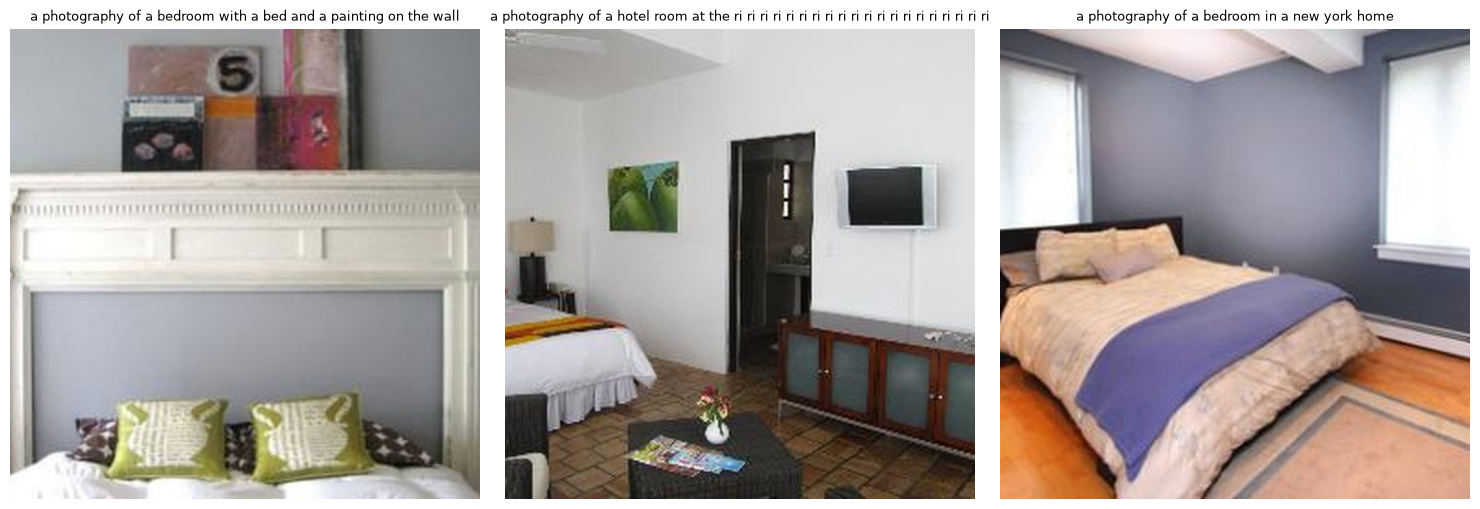

In [5]:
import json
from PIL import Image
import matplotlib.pyplot as plt

DATASET_DIR = Path(r"D:\LatentCraft\server\dataset\lsun_bedroom_2k")
metadata_file = DATASET_DIR / "metadata.jsonl"

records = []
with open(metadata_file, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line.strip()))

print(f"Total prepared dataset images: {len(records)}")

# Display 3 sample images with their BLIP generated captions
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, ax in enumerate(axes):
    sample = records[i]
    img_path = DATASET_DIR / sample["file_name"]
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(sample["text"], fontsize=9, wrap=True)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Load SD1.5 Base Model & Setup Memory-Optimized Pipeline
To fit within 6GB VRAM, we:
- Load in `torch.float16`.
- Precompute latents and text embeddings.
- Remove VAE and Text Encoder from GPU memory before UNet optimization.

In [6]:
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler
from peft import LoraConfig, get_peft_model, get_peft_model_state_dict

MODEL_ID = "runwayml/stable-diffusion-v1-5"
OUTPUT_DIR = Path(r"D:\LatentCraft\server\outputs\sd15_bedroom_lora")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading SD 1.5 pipeline components...")
tokenizer = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(MODEL_ID, subfolder="text_encoder", torch_dtype=torch.float16).to(device)
vae = AutoencoderKL.from_pretrained(MODEL_ID, subfolder="vae", torch_dtype=torch.float16).to(device)
unet = UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder="unet", torch_dtype=torch.float16).to(device)
noise_scheduler = DDPMScheduler.from_pretrained(MODEL_ID, subfolder="scheduler")

# Freeze base model components
vae.requires_grad_(False)
text_encoder.requires_grad_(False)
unet.requires_grad_(False)
print("Base model loaded and frozen successfully!")

Loading SD 1.5 pipeline components...


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 583.92it/s]


Base model loaded and frozen successfully!


## 4. Precompute Latents & Text Embeddings (VRAM Caching Phase)
Encoding all 2,000 images once and keeping them in CPU RAM lets us unload both VAE (~1.5GB) and CLIP Text Encoder (~1.2GB) completely from the GPU.

In [7]:
from tqdm.auto import tqdm

print("Precomputing VAE latents...")
all_latents = []
all_tokens = []
batch_size = 4

vae.eval()
with torch.no_grad():
    for i in tqdm(range(0, len(records), batch_size), desc="Caching Latents"):
        batch_records = records[i : i + batch_size]
        images = []
        prompts = []

        for r in batch_records:
            img_path = DATASET_DIR / r["file_name"]
            with Image.open(img_path) as img:
                img = img.convert("RGB").resize((512, 512))
                tensor_img = torch.from_numpy(
                    (torch.ByteTensor(torch.ByteStorage.from_buffer(img.tobytes()))
                     .view(512, 512, 3)
                     .numpy() / 127.5) - 1.0
                ).permute(2, 0, 1).float()
                images.append(tensor_img)
            prompts.append(r.get("text", "a photography of a bedroom"))

        img_tensors = torch.stack(images).to(device, dtype=torch.float16)
        latents = vae.encode(img_tensors).latent_dist.sample() * 0.18215
        all_latents.append(latents.cpu())

        tokens = tokenizer(
            prompts,
            padding="max_length",
            max_length=tokenizer.model_max_length,
            truncation=True,
            return_tensors="pt",
        ).input_ids
        all_tokens.append(tokens)

cached_latents = torch.cat(all_latents, dim=0)
cached_tokens = torch.cat(all_tokens, dim=0)

# Free VAE from GPU memory
del vae
torch.cuda.empty_cache()
print("VAE purged from VRAM to save memory!")

# Precompute text embeddings using text_encoder
print("Precomputing CLIP text embeddings...")
all_text_embeds = []
with torch.no_grad():
    for i in range(0, len(cached_tokens), 16):
        batch_tokens = cached_tokens[i : i + 16].to(device)
        embeds = text_encoder(batch_tokens)[0]
        all_text_embeds.append(embeds.cpu())
cached_embeds = torch.cat(all_text_embeds, dim=0)

# Free Text Encoder from GPU memory
del text_encoder
torch.cuda.empty_cache()
print("Text Encoder purged from VRAM!")
print(f"Cached {len(cached_latents)} latents and text embeddings.")

Precomputing VAE latents...


Caching Latents:   0%|          | 0/500 [00:00<?, ?it/s]C:\Users\deves\AppData\Local\Temp\ipykernel_28552\3118459334.py:20: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  (torch.ByteTensor(torch.ByteStorage.from_buffer(img.tobytes()))
Caching Latents:  10%|█         | 52/500 [16:00<2:17:50, 18.46s/it]


KeyboardInterrupt: 

## 5. Inject LoRA Adapters into UNet & Configure Training

In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from safetensors.torch import save_file

class CachedLatentDataset(Dataset):
    def __init__(self, latents, embeds):
        self.latents = latents
        self.embeds = embeds

    def __len__(self):
        return len(self.latents)

    def __getitem__(self, idx):
        return {
            "latents": self.latents[idx],
            "embeds": self.embeds[idx],
        }

# Enable gradient checkpointing to reduce activation memory
unet.enable_gradient_checkpointing()

# Configure LoRA on UNet cross & self-attention projections
lora_config = LoraConfig(
    r=16,
    lora_alpha=16,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],
)
unet = get_peft_model(unet, lora_config)
unet.print_trainable_parameters()

# Maintain float32 for trainable adapter weights for stable gradients in fp16
for param in unet.parameters():
    if param.requires_grad:
        param.data = param.data.to(torch.float32)

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, unet.parameters()),
    lr=1e-4,
    betas=(0.9, 0.999),
    weight_decay=1e-2,
    eps=1e-8,
)

dataset = CachedLatentDataset(cached_latents, cached_embeds)
dataloader = DataLoader(dataset, batch_size=1, shuffle=True)
print("LoRA injection complete and optimizer initialized!")

## 6. Run Training Loop (Interactive Loss & Checkpointing)

In [ ]:
NUM_EPOCHS = 10
GRAD_ACCUM = 4
SAVE_STEPS = 500

total_steps = (len(dataloader) // GRAD_ACCUM) * NUM_EPOCHS
global_step = 0
progress_bar = tqdm(total=total_steps, desc="Training LoRA")
loss_history = []

unet.train()
for epoch in range(NUM_EPOCHS):
    epoch_loss = 0.0
    optimizer.zero_grad()

    for step, batch in enumerate(dataloader):
        latents = batch["latents"].to(device, dtype=torch.float16)
        encoder_hidden_states = batch["embeds"].to(device, dtype=torch.float16)

        # Sample random noise and timesteps
        noise = torch.randn_like(latents)
        bsz = latents.shape[0]
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (bsz,), device=device).long()

        # Add noise to latents (Forward diffusion)
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        # Predict noise residual with LoRA UNet
        model_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

        loss = F.mse_loss(model_pred.float(), noise.float(), reduction="mean")
        loss = loss / GRAD_ACCUM
        loss.backward()

        epoch_loss += loss.item() * GRAD_ACCUM

        if (step + 1) % GRAD_ACCUM == 0 or (step + 1) == len(dataloader):
            torch.nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
            optimizer.step()
            optimizer.zero_grad()
            progress_bar.update(1)
            global_step += 1

            loss_val = loss.item() * GRAD_ACCUM
            loss_history.append(loss_val)
            progress_bar.set_postfix({"step": global_step, "loss": f"{loss_val:.4f}"})

            if global_step % SAVE_STEPS == 0:
                ckpt_dir = OUTPUT_DIR / f"checkpoint-{global_step}"
                ckpt_dir.mkdir(exist_ok=True)
                save_file(get_peft_model_state_dict(unet), str(ckpt_dir / "adapter_model.safetensors"))
                print(f"\nSaved checkpoint at step {global_step} to {ckpt_dir}")

    avg_loss = epoch_loss / len(dataloader)
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS} Finished | Average Loss: {avg_loss:.4f}")

# Final Save
final_path = OUTPUT_DIR / "final_bedroom_lora.safetensors"
save_file(get_peft_model_state_dict(unet), str(final_path))
print(f"\nTraining complete! Adapter saved to: {final_path}")

## 7. Plot Loss Curve & Generate Bedroom Designs

In [ ]:
# Plot the training loss trajectory
plt.figure(figsize=(10, 4))
plt.plot(loss_history, label="MSE Loss", color="purple", alpha=0.6)
plt.xlabel("Optimization Step")
plt.ylabel("Loss")
plt.title("Stable Diffusion 1.5 LoRA Training Loss (LSUN Bedroom)")
plt.grid(True)
plt.legend()
plt.show()

In [1]:
from diffusers import StableDiffusionPipeline

# Free training UNet from VRAM
del unet, optimizer
torch.cuda.empty_cache()

# Load full pipeline with our new LoRA weights for inference
pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    safety_checker=None,
).to(device)

final_lora = OUTPUT_DIR / "final_bedroom_lora.safetensors"
if final_lora.exists():
    pipe.load_lora_weights(str(final_lora.parent), weight_name=final_lora.name)
    print(f"Loaded trained Bedroom LoRA weights from {final_lora}")

test_prompt = "a photography of a modern luxury master bedroom with large glass windows, king bed, oak wood floor, 8k resolution"
generator = torch.Generator(device=device).manual_seed(123)

generated_img = pipe(
    prompt=test_prompt,
    negative_prompt="blurry, distorted, low quality, bad architecture, deformed",
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=generator,
).images[0]

plt.figure(figsize=(7, 7))
plt.imshow(generated_img)
plt.title(test_prompt, fontsize=10, wrap=True)
plt.axis("off")
plt.show()

generated_img.save(OUTPUT_DIR / "sample_bedroom_test.png")
print(f"Sample bedroom image saved to {OUTPUT_DIR / 'sample_bedroom_test.png'}")

D:\fast-design protype\gpu_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NameError: name 'unet' is not defined